# Real aluminium notch imaging

This review actively reconstructs the bound measured half-matrix capture. The hidden reference is an independently executed standard method, **not measured reflectivity truth**. The original example compares acquisition, trace filtering, and linear/dB TFM. Those comparisons remain below; we add pulse-echo and aperture/speed sensitivity to delimit the direct-wave model.

For element position $p_i$ and image point $r$, $\tau_i=||r-p_i||/c$. A fifth-order zero-phase0.5–6MHz filter and analytic transform give $q_{ij}$. The complex focused field is $b(r)=M^{-1}\sum_{ij}w_{ij}q_{ij}(\tau_i+\tau_j)$, with $M=2080$, $w=1$ on the diagonal and2 elsewhere. The reported image is $|b|$. Nearest time interpolation and zero outside the record match upstream.

**Visual contract.** Measured B-scan and trace show acquisition evidence; shared dB scales compare independently run upstream and fresh images; the difference panel exposes numerical mismatch. Pulse-echo, half-aperture and speed-mismatch images answer how acquisition/model assumptions affect focusing. No uncertainty bars are inferred from one measured field.

In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(root))
from src.main import run
from src.preprocessing import load_data,analytic_filter
from src.solvers import reconstruct
from src.visualization import acquisition_figure,comparison_figure,sensitivity_figure,agreement
plt.rcParams.update({'font.size':10,'axes.titlesize':11,'svg.fonttype':'none','pdf.fonttype':42})
data=load_data(root/'data/raw_data.npz')
t0=time.perf_counter();fresh=run(root/'data/raw_data.npz',root/'output/reconstruction.npz')[0];runtime=time.perf_counter()-t0
upstream=np.load(root/'notebooks/reference_outputs/upstream.npz')['reconstruction'][0]
print('Fresh CPU seconds:',runtime,'NCC, dynamic-range NRMSE:',agreement(fresh,upstream))


Fresh CPU seconds: 3.637876099906862 NCC, dynamic-range NRMSE: (1.0, 7.99205690381781e-17)


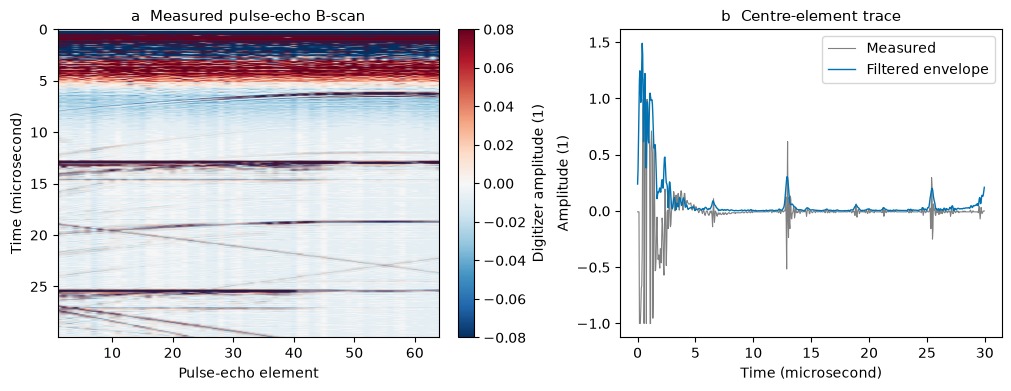

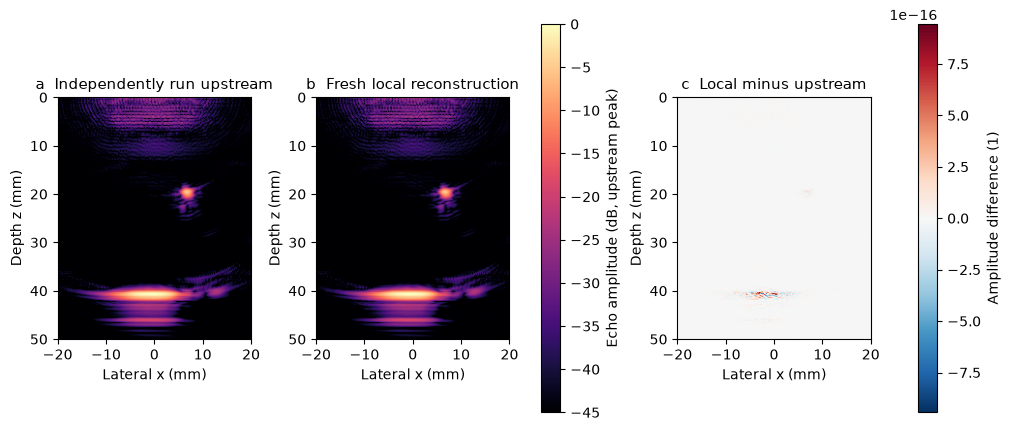

In [2]:
fig=acquisition_figure(data,analytic_filter(data['traces']));plt.show()
fig=comparison_figure(fresh,upstream);plt.show()


The parity difference reflects floating-point summation only. A successful comparison establishes extraction fidelity for this acquisition. Scattering strength, notch geometry and absolute material truth remain unmeasured. The next experiments recompute the same recorded data under acquisition/model changes; their differences are not reconstruction error against physical truth.

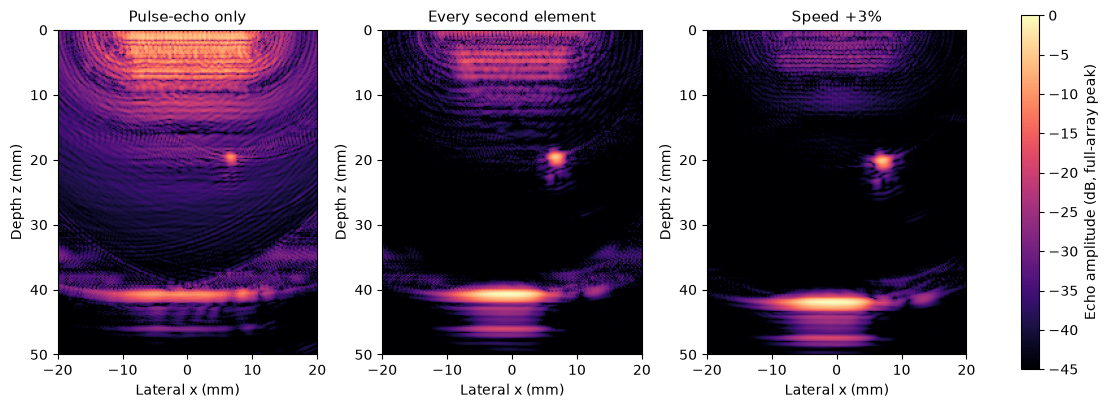

[
  {
    "method": "Full array",
    "ncc_vs_upstream": 1.0,
    "nrmse_vs_upstream": 7.99205690381781e-17,
    "peak_x_mm": -0.5999999999999979,
    "peak_z_mm": 40.800000000000004,
    "peak_amplitude": 0.2893434134257504
  },
  {
    "method": "Pulse-echo only",
    "ncc_vs_upstream": 0.38944913581657725,
    "nrmse_vs_upstream": 0.08262852270936352,
    "peak_x_mm": 1.2000000000000028,
    "peak_z_mm": 0.8,
    "peak_amplitude": 0.1845527461218514
  },
  {
    "method": "Every second element",
    "ncc_vs_upstream": 0.9692052689568728,
    "nrmse_vs_upstream": 0.015397808528126737,
    "peak_x_mm": -1.1999999999999993,
    "peak_z_mm": 40.800000000000004,
    "peak_amplitude": 0.2870296889461176
  },
  {
    "method": "Speed +3%",
    "ncc_vs_upstream": 0.36170547411514176,
    "nrmse_vs_upstream": 0.0698119645457603,
    "peak_x_mm": -0.3999999999999986,
    "peak_z_mm": 42.0,
    "peak_amplitude": 0.30022397047504906
  }
]


In [3]:
experiments={'Pulse-echo only':reconstruct(data,pulse_echo=True),'Every second element':reconstruct(data,channel_step=2),'Speed +3%':reconstruct(data,speed=6300*1.03)}
fig=sensitivity_figure(experiments,fresh);plt.show()
rows=[]
for method,img in {'Full array':fresh,**experiments}.items():
    ncc,nrmse=agreement(img,upstream);iz,ix=np.unravel_index(img.argmax(),img.shape)
    rows.append({'method':method,'ncc_vs_upstream':ncc,'nrmse_vs_upstream':nrmse,'peak_x_mm':-20+.2*ix,'peak_z_mm':.2*iz,'peak_amplitude':float(img.max())})
print(json.dumps(rows,indent=2))
np.savez_compressed(root/'notebooks/reference_outputs/fresh_measurements.npz',reconstruction=fresh[None],pulse_echo=experiments['Pulse-echo only'],half_aperture=experiments['Every second element'],speed_mismatch=experiments['Speed +3%'],runtime_seconds=np.array(runtime))


In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('local_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,code=judge.evaluate(root/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert code==0


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0,
    "reconstruction_nrmse": 7.99205690381781e-17
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    }
  },
  "errors": []
}


The local implementation reproduces the recorded-pair normalization, reciprocity weights, bandpass and sample rounding of the independent upstream run. Pulse-echo and aperture restrictions expose information loss; incorrect speed changes focus and amplitude. These are comparisons on the measured example, not a claim of independently validated notch dimensions or quantitative reflectivity.